# Custom CNN (Model Building)

This notebook builds a Convolutional Neural Network (CNN) for classifying plant leaf images into different disease and healthy categories.

The model will be trained using the preprocessed PlantVillage dataset.

# CNN image ke andar patterns dhundhta hai.
# CNN  architecture 

Input Image
(256 × 256 × 3) 
RGB plant-leaf image model ko input milegi.  

        ↓
     Conv2D
   32 Filters
      (3×3)  Image se basic features jaise edges, lines aur simple textures learn karega.

        ↓
      ReLU  Negative values ko 0 karta hai aur positive values ko retain karta hai.

        ↓
   MaxPooling2D  Feature map ka spatial size reduce karta hai aur important/high activations retain karta hai.
      (2×2)

        ↓
     Conv2D
   64 Filters
      (3×3)
      Pehle layer ke basic features ko combine karke more complex patterns learn karega.

        ↓
      ReLU

        ↓
   MaxPooling2D
      (2×2)
      Phir se spatial dimensions reduce karega.

        ↓
     Conv2D
   128 Filters
      (3×3)
      Aur deeper/more complex features learn karega, potentially disease-related patterns.

        ↓
      ReLU Third convolution ke output par non-linearity apply karega.

        ↓
GlobalAveragePooling2D
Isliye huge 460,800 values ko Dense layer me bhejne ke bajay sirf 128 values milti hain.

        ↓
    Dense (128)  
      ReLU  Learned features ko combine karke classification decision ke liye useful representation banata hai.
      
        ↓
    Dense (36)
     Softmax
     Tumhare dataset me 36 classes hain, isliye 36 output neurons.

        ↓
   Predicted Disease


In [1]:
import os
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt


In [2]:
dataset_path = r"D:\Krishi-Sahayak\ml\Plant_disease_detection\dataset\plant_village"
print(dataset_path)

D:\Krishi-Sahayak\ml\Plant_disease_detection\dataset\plant_village


In [3]:
IMG_SIZE = (256,256) # Resize images to 256x256 pixels

In [4]:
BATCH_SIZE = 32 # no of images to process in a batch

In [5]:
# to load training dataset

train_dataset = tf.keras.utils.image_dataset_from_directory(  #function to load images from directory and create a tensorflow dataset with llabels
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 50500 files belonging to 36 classes.
Using 40400 files for training.


In [6]:
# validation dataset  


validation_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)



Found 50500 files belonging to 36 classes.
Using 10100 files for validation.


In [7]:
val_batches = tf.data.experimental.cardinality(validation_dataset)

print("Validation batches:", val_batches.numpy())

Validation batches: 316


In [8]:
test_dataset = validation_dataset.take(val_batches // 2)
validation_dataset = validation_dataset.skip(val_batches // 2)

In [9]:
print("Train batches:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Validation batches:", tf.data.experimental.cardinality(validation_dataset).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_dataset).numpy())

Train batches: 1263
Validation batches: 158
Test batches: 158


In [10]:
normalization_layer = tf.keras.layers.Rescaling(1./255)  #means we are scaling the pixel values from 0-255 to 0-1  1. means pixel/255

In [11]:
#applied on the trained dataset
train_dataset = train_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

In [12]:
validation_dataset = validation_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

In [13]:
test_dataset = test_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

In [14]:
for images, labels in train_dataset.take(1):
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [15]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(256, 256, 3)),
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

In [16]:
for images, labels in train_dataset.take(1):
    augmented_images = data_augmentation(images)
    print("Original shape:", images.shape)
    print("Augmented shape:", augmented_images.shape)

Original shape: (32, 256, 256, 3)
Augmented shape: (32, 256, 256, 3)


In [17]:
for images, labels in train_dataset.take(1):
    sample_image = images[0]
    sample_label = labels[0]
    break

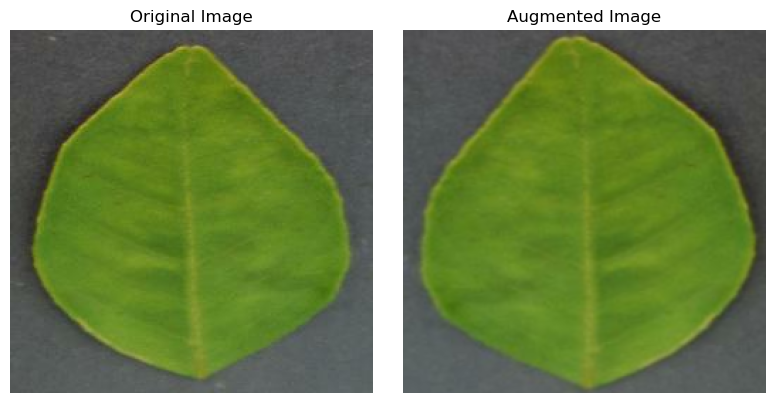

In [18]:
# comparison between original image and augmented image

# sample test
import numpy as np

sample_image_batch = tf.expand_dims(sample_image, axis=0)

augmented_image_batch = data_augmentation(sample_image_batch)

augmented_image = augmented_image_batch[0]

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(sample_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(augmented_image)
plt.title("Augmented Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:
train_dataset = train_dataset.map(
    lambda x, y: (data_augmentation(x), y)
)

In [20]:
for images, labels in train_dataset.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)

Images shape: (32, 256, 256, 3)
Labels shape: (32,)


In [21]:
# prefetching the dataset to improve performance

AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)


In [22]:
for images, labels in train_dataset.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image shape: (32, 256, 256, 3)
Label shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 0.9521605


In [23]:
classes = os.listdir(dataset_path)

In [24]:
print("Number of classes:", len(classes))
print("Classes:")
for i, class_name in enumerate(classes):
    print(i, ":", class_name)

Number of classes: 36
Classes:
0 : Apple___Apple_scab
1 : Apple___Black_rot
2 : Apple___Cedar_apple_rust
3 : Apple___healthy
4 : Blueberry___healthy
5 : Cherry_(including_sour)___healthy
6 : Cherry_(including_sour)___Powdery_mildew
7 : Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
8 : Corn_(maize)___Common_rust_
9 : Corn_(maize)___healthy
10 : Corn_(maize)___Northern_Leaf_Blight
11 : Grape___Black_rot
12 : Grape___Esca_(Black_Measles)
13 : Grape___healthy
14 : Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
15 : Orange___Haunglongbing_(Citrus_greening)
16 : Peach___Bacterial_spot
17 : Peach___healthy
18 : Pepper,_bell___Bacterial_spot
19 : Pepper,_bell___healthy
20 : Potato___Early_blight
21 : Potato___healthy
22 : Potato___Late_blight
23 : Raspberry___healthy
24 : Soybean___healthy
25 : Squash___Powdery_mildew
26 : Strawberry___healthy
27 : Strawberry___Leaf_scorch
28 : Tomato___Bacterial_spot
29 : Tomato___Early_blight
30 : Tomato___Late_blight
31 : Tomato___Leaf_Mold
32 : Tomato___S

In [25]:
# no of classes
class_names = sorted(os.listdir(dataset_path))

num_classes = len(class_names)

print("Number of classes:", num_classes)
print(class_names)

Number of classes: 36
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite

In [26]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(256, 256, 3)),
])  #32 mtlb 32 filters, 3x3 kernel size, relu activation function, input shape of 256x256 with 3 channels (RGB)

d:\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [27]:
model.summary()     #formula used = output size = input size - filter size +1
# 256 - 3 + 1 = 254

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 896 (3.50 KB)

 Trainable params: 896 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

# maxpooling


In [28]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(256, 256, 3)),
    layers.MaxPooling2D((2, 2))
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 896 (3.50 KB)

 Trainable params: 896 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

None is the batch size , 254x254 convolution k naad spatial size (formula use krke) , 32 filters 

 maxpooling2d(2,2) kyuki window dimeansion ko half kr deti h but 32 channels will remain the same , pooling se only height aur width reduce hori h

 Conv2D
→ learns parameters ✅

MaxPooling
→ no parameters ❌
→ only reduces spatial dimensions


In [29]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(256, 256, 3)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
])

In [30]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,392 (75.75 KB)

 Trainable params: 19,392 (75.75 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(256, 256, 3)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
])

In [32]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,248 (364.25 KB)

 Trainable params: 93,248 (364.25 KB)

 Non-trainable params: 0 (0.00 B)

In [33]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(256, 256, 3)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),

    layers.GlobalAveragePooling2D()

    
])

In [34]:
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,248 (364.25 KB)

 Trainable params: 93,248 (364.25 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
model = models.Sequential([
    layers.Input(shape=(256, 256, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),

    layers.Dense(num_classes, activation="softmax")
])

In [36]:
model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 36)             │         4,644 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 114,404 (446.89 KB)

 Trainable params: 114,404 (446.89 KB)

 Non-trainable params: 0 (0.00 B)

# Compile
Optimizer
   ↓
Weights ko update kaise karna hai?

Loss Function
   ↓
Prediction kitni wrong hai?

Metric
   ↓
Performance ko kaise measure karna hai?

In [37]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [38]:
model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 36)             │         4,644 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 114,404 (446.89 KB)

 Trainable params: 114,404 (446.89 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:
print(tf.config.list_physical_devices('GPU'))

[]


In [40]:
print("Train batches:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Validation batches:", tf.data.experimental.cardinality(validation_dataset).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_dataset).numpy())

Train batches: 1263
Validation batches: 158
Test batches: 158


# Training

In [41]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [82]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10,
    callbacks=[early_stopping]
)

Epoch 1/10
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 1866s 1s/step - accuracy: 0.6393 - loss: 1.1864 - val_accuracy: 0.5192 - val_loss: 1.9177
Epoch 2/10
   3/1263 ━━━━━━━━━━━━━━━━━━━━ 36:15 2s/step - accuracy: 0.7118 - loss: 0.8893

KeyboardInterrupt: 

In [58]:
best_epoch = np.argmin(history.history["val_loss"]) + 1

print("Best Epoch:", best_epoch)
print("Best Validation Loss:", min(history.history["val_loss"]))
print("Best Validation Accuracy:", history.history["val_accuracy"][best_epoch - 1])


NameError: name 'history' is not defined

In [83]:
model.save("custom_cnn_best.keras")

In [84]:
# Evaluate model on test dataset

test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

158/158 ━━━━━━━━━━━━━━━━━━━━ 47s 298ms/step - accuracy: 0.6489 - loss: 1.2533
Test Loss: 1.2533047199249268
Test Accuracy: 0.6489319801330566


In [85]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [86]:
import tensorflow as tf

# Load the saved best CNN model
best_model = tf.keras.models.load_model(
    "custom_cnn_best.keras"
)

print("Model loaded successfully!")
best_model.summary()

Model loaded successfully!


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 36)             │         4,644 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 343,214 (1.31 MB)

 Trainable params: 114,404 (446.89 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 228,810 (893.79 KB)

In [87]:
saved_test_loss, saved_test_accuracy = best_model.evaluate(test_dataset)

print("Saved Model Test Loss:", saved_test_loss)
print("Saved Model Test Accuracy:", saved_test_accuracy)

158/158 ━━━━━━━━━━━━━━━━━━━━ 44s 275ms/step - accuracy: 0.6472 - loss: 1.2528
Saved Model Test Loss: 1.2528297901153564
Saved Model Test Accuracy: 0.6471518874168396


In [57]:
print("Number of classes:", len(class_names))
print("Number of test classes:", len(test_dataset.class_names))

print("\nClass names:")
print(class_names)

print("\nTest class names:")
print(test_dataset.class_names)

Number of classes: 36


AttributeError: '_PrefetchDataset' object has no attribute 'class_names'

In [88]:
print(class_names)

['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Sp

In [89]:
import os

folder = r"D:\Krishi-Sahayak\ml\Plant_disease_detection\dataset\plant_village\Tomato___Late_blight"

files = os.listdir(folder)

print(files[:5])

['0003faa8-4b27-4c65-bf42-6d9e352ca1a5___RS_Late.B 4946.JPG', '00355ec2-f12c-4015-b8f9-94354f69ce22___RS_Late.B 5311.JPG', '005a2c1f-4e15-49e4-9e5c-61dc3ecf9708___RS_Late.B 5096.JPG', '005e3b43-9050-47da-9498-f9ecdcc703b3___RS_Late.B 5104.JPG', '008ebb44-eb77-4843-b621-4b88b5df7d43___RS_Late.B 5188.JPG']


# Single image prediction

In [90]:
from PIL import Image
import numpy as np

image_path = r"D:\Krishi-Sahayak\ml\Plant_disease_detection\dataset\plant_village\Tomato___Late_blight\0003faa8-4b27-4c65-bf42-6d9e352ca1a5___RS_Late.B 4946.JPG"

img = Image.open(image_path).convert("RGB")
img = img.resize((256, 256))

img_array = np.array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

predictions = best_model.predict(img_array)

predicted_index = np.argmax(predictions[0])
predicted_class = class_names[predicted_index]
confidence = predictions[0][predicted_index] * 100

print("Predicted Disease:", predicted_class)
print("Confidence:", round(confidence, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
Predicted Disease: Tomato___Late_blight
Confidence: 67.59 %


In [91]:
from PIL import Image
import numpy as np

def predict_disease(image_path):
    # Load image
    img = Image.open(image_path).convert("RGB")

    # Resize to model input size
    img = img.resize((256, 256))

    # Convert to numpy array
    img_array = np.array(img)

    # Normalize pixel values
    img_array = img_array / 255.0

    # Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)

    # Prediction
    predictions = best_model.predict(img_array, verbose=0)

    # Get predicted class
    predicted_index = np.argmax(predictions[0])
    predicted_class = class_names[predicted_index]

    # Get confidence
    confidence = predictions[0][predicted_index] * 100

    return predicted_class, confidence

In [92]:
image_path = r"D:\Krishi-Sahayak\ml\Plant_disease_detection\dataset\plant_village\Tomato___Late_blight\0003faa8-4b27-4c65-bf42-6d9e352ca1a5___RS_Late.B 4946.JPG"

disease, confidence = predict_disease(image_path)

print("Predicted Disease:", disease)
print("Confidence:", round(confidence, 2), "%")


Predicted Disease: Tomato___Late_blight
Confidence: 67.59 %


In [93]:
def format_prediction(predicted_class, confidence):
    # Split plant and disease
    plant, disease = predicted_class.split("___")

    # Make names user-friendly
    plant = plant.replace("_", " ")
    disease = disease.replace("_", " ")

    return {
        "plant": plant,
        "disease": disease,
        "confidence": round(float(confidence), 2)
    }

In [94]:
result = format_prediction(disease, confidence)

print("Plant:", result["plant"])
print("Disease:", result["disease"])
print("Confidence:", result["confidence"], "%")

Plant: Tomato
Disease: Late blight
Confidence: 67.59 %


# final prediction result

In [95]:
def predict_plant_disease(image_path):
    # Load image
    img = Image.open(image_path).convert("RGB")

    # Resize
    img = img.resize((256, 256))

    # Convert to array and normalize
    img_array = np.array(img) / 255.0

    # Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)

    # Model prediction
    predictions = best_model.predict(img_array, verbose=0)

    # Get predicted class
    predicted_index = np.argmax(predictions[0])
    predicted_class = class_names[predicted_index]

    # Confidence
    confidence = predictions[0][predicted_index] * 100

    # Format result
    plant, disease = predicted_class.split("___")

    plant = plant.replace("_", " ")
    disease = disease.replace("_", " ")

    return {
        "plant": plant,
        "disease": disease,
        "confidence": round(float(confidence), 2)
    }



In [96]:
image_path = r"D:\Krishi-Sahayak\ml\Plant_disease_detection\dataset\plant_village\Tomato___Late_blight\0003faa8-4b27-4c65-bf42-6d9e352ca1a5___RS_Late.B 4946.JPG"

result = predict_plant_disease(image_path)

print(result)

{'plant': 'Tomato', 'disease': 'Late blight', 'confidence': 67.59}


In [97]:
def predict_top3(image_path):
    # Load image
    img = Image.open(image_path).convert("RGB")
    img = img.resize((256, 256))

    # Preprocess
    img_array = np.array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Prediction
    predictions = best_model.predict(img_array, verbose=0)[0]

    # Get top 3 indexes
    top3_indices = np.argsort(predictions)[-3:][::-1]

    results = []

    for index in top3_indices:
        class_name = class_names[index]
        confidence = predictions[index] * 100

        plant, disease = class_name.split("___")

        results.append({
            "plant": plant.replace("_", " "),
            "disease": disease.replace("_", " "),
            "confidence": round(float(confidence), 2)
        })

    return results

In [98]:
top3 = predict_top3(image_path)

for i, prediction in enumerate(top3, start=1):
    print(
        f"{i}. {prediction['plant']} - "
        f"{prediction['disease']} - "
        f"{prediction['confidence']}%"
    )

1. Tomato - Late blight - 67.59%
2. Apple - healthy - 19.2%
3. Tomato - Leaf Mold - 7.59%


In [99]:
# Create disease information structure for ALL 36 classes

disease_info = {}

for class_name in class_names:
    disease_info[class_name] = {
        "symptoms": [],
        "prevention": [],
        "management": []
    }

print("Total classes:", len(disease_info))
print("\nFirst 5 classes:")

for i, class_name in enumerate(disease_info.keys()):
    if i == 5:
        break
    print(f"{i+1}. {class_name}")



Total classes: 36

First 5 classes:
1. Apple___Apple_scab
2. Apple___Black_rot
3. Apple___Cedar_apple_rust
4. Apple___healthy
5. Blueberry___healthy


In [100]:
def predict_plant_disease(image_path):
    # Load image
    img = Image.open(image_path).convert("RGB")
    img = img.resize((256, 256))

    # Preprocess
    img_array = np.array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Model prediction
    predictions = best_model.predict(img_array, verbose=0)[0]

    # Get predicted class
    predicted_index = np.argmax(predictions)
    predicted_class = class_names[predicted_index]

    # Confidence
    confidence = predictions[predicted_index] * 100

    # Get disease information for predicted class
    info = disease_info[predicted_class]

    # Format plant and disease name
    plant, disease = predicted_class.split("___")

    return {
        "plant": plant.replace("_", " "),
        "disease": disease.replace("_", " "),
        "confidence": round(float(confidence), 2),
        "symptoms": info["symptoms"],
        "prevention": info["prevention"],
        "management": info["management"]
    }

In [101]:
result = predict_plant_disease(image_path)

print("Plant:", result["plant"])
print("Disease:", result["disease"])
print("Confidence:", result["confidence"], "%")
print("Symptoms:", result["symptoms"])
print("Prevention:", result["prevention"])
print("Management:", result["management"])

Plant: Tomato
Disease: Late blight
Confidence: 67.59 %
Symptoms: []
Prevention: []
Management: []


In [102]:
# Disease information for all 36 classes

disease_info = {

    # ================= APPLE =================
    "Apple___Apple_scab": {
        "symptoms": [
            "Olive-green to brown spots on leaves",
            "Spots become dark brown or black as they develop",
            "Brown corky lesions may appear on fruit",
            "Severe infections can cause premature leaf drop and deformed fruit"
        ],
        "prevention": [
            "Remove fallen infected leaves and fruit debris",
            "Maintain good air circulation and avoid prolonged leaf wetness",
            "Use disease-resistant varieties where available"
        ],
        "management": [
            "Remove infected plant debris",
            "Prune to improve air circulation",
            "Monitor plants during wet spring conditions",
            "Use locally recommended fungicide programs when necessary"
        ]
    },

    "Apple___Black_rot": {
        "symptoms": [
            "Round leaf spots with purple margins and tan centers",
            "Brown circular lesions may develop on fruit",
            "Fruit can become firm, rotten and eventually mummified",
            "Dark cankers may develop on branches"
        ],
        "prevention": [
            "Remove mummified fruit from the tree and ground",
            "Prune dead and diseased branches",
            "Avoid unnecessary plant stress"
        ],
        "management": [
            "Remove infected branches and fruit",
            "Improve orchard sanitation",
            "Monitor trees regularly for new lesions",
            "Follow locally recommended disease-control measures"
        ]
    },

    "Apple___Cedar_apple_rust": {
        "symptoms": [
            "Yellow spots develop on leaves and become bright orange-red",
            "Black dots may appear in the center of leaf spots",
            "Orange structures may develop on the underside of leaves",
            "Fruit may develop rough green to brown spots"
        ],
        "prevention": [
            "Choose resistant apple varieties when available",
            "Avoid planting susceptible apples close to cedar or juniper hosts",
            "Remove infected plant material where practical"
        ],
        "management": [
            "Monitor nearby cedar and juniper plants",
            "Remove infected galls from nearby hosts when practical",
            "Use appropriate preventive disease-control measures when required"
        ]
    },

    "Apple___healthy": {
        "symptoms": [
            "No visible disease symptoms",
            "Leaves and fruit show normal healthy development"
        ],
        "prevention": [
            "Maintain proper irrigation and nutrition",
            "Keep the growing area clean",
            "Regularly inspect plants for early disease symptoms"
        ],
        "management": [
            "Continue routine plant monitoring",
            "Maintain good orchard sanitation and plant health"
        ]
    },


    # ================= BLUEBERRY =================
    "Blueberry___healthy": {
        "symptoms": [
            "No visible disease symptoms",
            "Leaves, shoots and fruit develop normally"
        ],
        "prevention": [
            "Maintain good air circulation",
            "Avoid excessive moisture around foliage",
            "Remove diseased plant debris"
        ],
        "management": [
            "Continue regular monitoring",
            "Maintain balanced nutrition and irrigation",
            "Remove damaged or diseased plant material promptly"
        ]
    },


    # ================= CHERRY =================
    "Cherry_(including_sour)___Powdery_mildew": {
        "symptoms": [
            "White powdery fungal growth on leaves and shoots",
            "Leaves may curl or become distorted",
            "Young shoots can show reduced growth"
        ],
        "prevention": [
            "Provide good air circulation",
            "Avoid excessive nitrogen fertilization",
            "Remove heavily infected plant material"
        ],
        "management": [
            "Monitor young leaves and shoots regularly",
            "Prune to improve airflow",
            "Use locally recommended disease-control measures when necessary"
        ]
    },

    "Cherry_(including_sour)___healthy": {
        "symptoms": [
            "No visible disease symptoms",
            "Leaves and fruit develop normally"
        ],
        "prevention": [
            "Maintain good orchard sanitation",
            "Provide adequate irrigation and nutrition",
            "Monitor plants regularly"
        ],
        "management": [
            "Continue routine monitoring",
            "Remove damaged or diseased plant material if detected"
        ]
    },


    # ================= CORN =================
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot": {
        "symptoms": [
            "Gray to tan rectangular lesions develop on leaves",
            "Lesions may enlarge and merge",
            "Severe infection can cause premature leaf death"
        ],
        "prevention": [
            "Rotate crops where practical",
            "Manage crop residue appropriately",
            "Use resistant hybrids where available"
        ],
        "management": [
            "Monitor lower leaves for early symptoms",
            "Improve field sanitation and crop rotation",
            "Use locally recommended disease-control practices"
        ]
    },

    "Corn_(maize)___Common_rust_": {
        "symptoms": [
            "Small reddish-brown to rust-colored pustules appear on leaves",
            "Pustules may occur on both leaf surfaces",
            "Severe infections can reduce photosynthetic leaf area"
        ],
        "prevention": [
            "Use resistant hybrids where available",
            "Monitor fields regularly",
            "Avoid unnecessary plant stress"
        ],
        "management": [
            "Scout fields during favorable disease conditions",
            "Use resistant varieties when available",
            "Apply locally recommended management practices when disease pressure is high"
        ]
    },

    "Corn_(maize)___Northern_Leaf_Blight": {
        "symptoms": [
            "Long gray-green to tan cigar-shaped lesions develop on leaves",
            "Lesions enlarge and may merge",
            "Severe disease can cause extensive leaf blighting"
        ],
        "prevention": [
            "Use resistant hybrids",
            "Rotate crops where practical",
            "Manage infected crop residue"
        ],
        "management": [
            "Monitor fields regularly",
            "Use crop rotation and resistant varieties",
            "Follow local disease-management recommendations when disease pressure is high"
        ]
    },

    "Corn_(maize)___healthy": {
        "symptoms": [
            "No visible disease symptoms",
            "Leaves remain green and healthy"
        ],
        "prevention": [
            "Use healthy seed",
            "Maintain balanced nutrition and irrigation",
            "Monitor plants regularly"
        ],
        "management": [
            "Continue routine field scouting",
            "Maintain good crop management practices"
        ]
    },


    # ================= GRAPE =================
    "Grape___Black_rot": {
        "symptoms": [
            "Brown circular lesions may appear on leaves",
            "Dark spots can develop on fruit",
            "Infected berries may shrivel and become black mummies"
        ],
        "prevention": [
            "Remove infected berries and plant debris",
            "Improve canopy air circulation",
            "Avoid prolonged moisture on foliage"
        ],
        "management": [
            "Remove infected fruit and plant material",
            "Prune dense canopy growth",
            "Monitor during warm and humid weather",
            "Use locally recommended disease-control measures"
        ]
    },

    "Grape___Esca_(Black_Measles)": {
        "symptoms": [
            "Leaves may develop yellow areas with dark spots",
            "Fruit may develop dark spotting",
            "Severely affected shoots or vines may show dieback"
        ],
        "prevention": [
            "Use healthy planting material",
            "Avoid unnecessary trunk and pruning injuries",
            "Maintain vineyard sanitation"
        ],
        "management": [
            "Remove severely affected plant parts where practical",
            "Disinfect pruning equipment",
            "Monitor vines regularly for symptom development"
        ]
    },

    "Grape___Leaf_blight_(Isariopsis_Leaf_Spot)": {
        "symptoms": [
            "Dark brown to reddish leaf spots",
            "Spots may enlarge and cause leaf blighting",
            "Severe infection can result in premature leaf loss"
        ],
        "prevention": [
            "Improve canopy airflow",
            "Remove infected fallen leaves",
            "Avoid excessive canopy moisture"
        ],
        "management": [
            "Prune dense growth",
            "Remove infected plant debris",
            "Monitor vines regularly",
            "Use locally recommended disease-management practices"
        ]
    },

    "Grape___healthy": {
        "symptoms": [
            "No visible disease symptoms",
            "Leaves, shoots and fruit appear healthy"
        ],
        "prevention": [
            "Maintain vineyard sanitation",
            "Provide adequate irrigation and nutrition",
            "Ensure good canopy ventilation"
        ],
        "management": [
            "Continue regular vineyard scouting",
            "Remove diseased material if symptoms appear"
        ]
    },


    # ================= ORANGE =================
    "Orange___Haunglongbing_(Citrus_greening)": {
        "symptoms": [
            "Leaves may show uneven yellowing or blotchy mottling",
            "Shoots may show yellowing and decline",
            "Fruit can remain small, poorly colored or develop uneven coloration",
            "Affected trees may show reduced productivity"
        ],
        "prevention": [
            "Use certified disease-free planting material",
            "Monitor and manage the insect vector",
            "Remove infected trees according to local citrus-management recommendations"
        ],
        "management": [
            "Scout regularly for symptoms and vector insects",
            "Follow local citrus greening management programs",
            "Remove infected trees where recommended",
            "Maintain healthy nutrition and irrigation"
        ]
    },


    # ================= PEACH =================
    "Peach___Bacterial_spot": {
        "symptoms": [
            "Small dark or water-soaked spots may appear on leaves",
            "Leaf spots can enlarge and cause premature leaf drop",
            "Fruit may develop small sunken lesions"
        ],
        "prevention": [
            "Use healthy planting material",
            "Choose less susceptible varieties where available",
            "Avoid excessive leaf wetness"
        ],
        "management": [
            "Remove severely affected plant material",
            "Improve orchard airflow",
            "Monitor during warm and wet conditions",
            "Follow locally recommended bacterial-disease management"
        ]
    },

    "Peach___healthy": {
        "symptoms": [
            "No visible disease symptoms",
            "Leaves and fruit develop normally"
        ],
        "prevention": [
            "Maintain orchard sanitation",
            "Provide balanced nutrition and irrigation",
            "Regularly inspect plants"
        ],
        "management": [
            "Continue routine monitoring",
            "Remove diseased material if symptoms appear"
        ]
    },


    # ================= PEPPER =================
    "Pepper,_bell___Bacterial_spot": {
        "symptoms": [
            "Small water-soaked or dark leaf spots",
            "Spots may enlarge and cause leaf damage",
            "Fruit may develop raised or scabby lesions"
        ],
        "prevention": [
            "Use pathogen-free seed and healthy transplants",
            "Avoid overhead irrigation",
            "Practice crop rotation"
        ],
        "management": [
            "Remove infected plant debris",
            "Improve field sanitation",
            "Avoid working with wet plants",
            "Follow locally recommended bacterial disease-management practices"
        ]
    },

    "Pepper,_bell___healthy": {
        "symptoms": [
            "No visible disease symptoms",
            "Leaves and fruit develop normally"
        ],
        "prevention": [
            "Use healthy planting material",
            "Maintain proper irrigation and nutrition",
            "Monitor plants regularly"
        ],
        "management": [
            "Continue routine monitoring",
            "Remove diseased material if symptoms develop"
        ]
    },


    # ================= POTATO =================
    "Potato___Early_blight": {
        "symptoms": [
            "Dark brown circular spots with concentric rings on leaves",
            "Older leaves are often affected first",
            "Severe infection causes leaf yellowing and premature defoliation"
        ],
        "prevention": [
            "Use healthy seed tubers",
            "Practice crop rotation",
            "Remove infected crop debris",
            "Maintain adequate plant nutrition"
        ],
        "management": [
            "Monitor older leaves for early lesions",
            "Remove infected debris after harvest",
            "Maintain adequate plant vigor",
            "Use locally recommended disease-control measures"
        ]
    },

    "Potato___Late_blight": {
        "symptoms": [
            "Water-soaked irregular lesions on leaves",
            "Lesions rapidly become brown or dark",
            "White-gray fungal growth may appear under humid conditions",
            "Tubers can develop brown internal rot"
        ],
        "prevention": [
            "Use certified healthy seed tubers",
            "Avoid overhead irrigation where possible",
            "Maintain good field airflow",
            "Remove volunteer potato plants and infected debris"
        ],
        "management": [
            "Scout frequently during cool and humid conditions",
            "Remove infected plant material",
            "Destroy crop debris after harvest",
            "Use locally recommended fungicide programs when necessary"
        ]
    },

    "Potato___healthy": {
        "symptoms": [
            "No visible disease symptoms",
            "Leaves remain green and healthy",
            "Tubers develop normally"
        ],
        "prevention": [
            "Use certified healthy seed",
            "Practice crop rotation",
            "Maintain balanced irrigation and nutrition"
        ],
        "management": [
            "Continue regular field monitoring",
            "Maintain good crop sanitation"
        ]
    },


    # ================= RASPBERRY =================
    "Raspberry___healthy": {
        "symptoms": [
            "No visible disease symptoms",
            "Leaves, canes and fruit develop normally"
        ],
        "prevention": [
            "Maintain good air circulation",
            "Remove dead or diseased canes",
            "Avoid excessive moisture around foliage"
        ],
        "management": [
            "Continue regular scouting",
            "Prune and remove diseased canes if symptoms appear"
        ]
    },


    # ================= SOYBEAN =================
    "Soybean___healthy": {
        "symptoms": [
            "No visible disease symptoms",
            "Leaves and pods develop normally"
        ],
        "prevention": [
            "Use healthy seed",
            "Practice crop rotation",
            "Maintain balanced soil fertility and irrigation"
        ],
        "management": [
            "Scout fields regularly",
            "Maintain good crop management practices"
        ]
    },


    # ================= SQUASH =================
    "Squash___Powdery_mildew": {
        "symptoms": [
            "White powdery patches appear on leaves",
            "Infected leaves may become yellow or brown",
            "Severe infection can reduce photosynthesis"
        ],
        "prevention": [
            "Provide good air circulation",
            "Avoid excessive nitrogen fertilization",
            "Choose resistant varieties where available"
        ],
        "management": [
            "Remove severely affected leaves when practical",
            "Improve airflow around plants",
            "Monitor plants regularly",
            "Use locally recommended disease-control measures"
        ]
    },


    # ================= STRAWBERRY =================
    "Strawberry___Leaf_scorch": {
        "symptoms": [
            "Dark purple to reddish spots appear on leaves",
            "Spots may enlarge and develop brown centers",
            "Severe infection can cause leaf scorch and reduced plant vigor"
        ],
        "prevention": [
            "Remove infected leaves and debris",
            "Improve air circulation",
            "Avoid prolonged leaf wetness"
        ],
        "management": [
            "Remove severely infected leaves",
            "Maintain field sanitation",
            "Monitor plants regularly",
            "Use locally recommended disease-management practices"
        ]
    },

    "Strawberry___healthy": {
        "symptoms": [
            "No visible disease symptoms",
            "Leaves and fruit develop normally"
        ],
        "prevention": [
            "Use healthy planting material",
            "Maintain good field sanitation",
            "Provide balanced irrigation and nutrition"
        ],
        "management": [
            "Continue routine monitoring",
            "Remove diseased plant material if symptoms appear"
        ]
    },


    # ================= TOMATO =================
    "Tomato___Bacterial_spot": {
        "symptoms": [
            "Water-soaked areas develop on leaves",
            "Spots become dark brown or black",
            "Fruit may develop small sunken or scabby spots"
        ],
        "prevention": [
            "Use pathogen-free seed and healthy transplants",
            "Avoid overhead irrigation",
            "Practice crop rotation",
            "Remove infected plant debris"
        ],
        "management": [
            "Remove infected plant material",
            "Avoid working with wet plants",
            "Improve field sanitation",
            "Use locally recommended bacterial disease-control measures"
        ]
    },

    "Tomato___Early_blight": {
        "symptoms": [
            "Dark brown circular lesions with concentric rings",
            "Older leaves are usually affected first",
            "Severe infection can cause leaf yellowing and defoliation"
        ],
        "prevention": [
            "Remove infected crop debris",
            "Maintain good plant spacing and airflow",
            "Avoid prolonged leaf wetness",
            "Use healthy transplants"
        ],
        "management": [
            "Remove severely infected leaves",
            "Maintain field sanitation",
            "Avoid overhead irrigation where possible",
            "Use locally recommended disease-control measures"
        ]
    },

    "Tomato___Late_blight": {
        "symptoms": [
            "Small water-soaked areas rapidly enlarge into brown or purple-brown blotches",
            "White-gray fungal growth may appear under humid conditions",
            "Leaves can die rapidly",
            "Fruit may develop firm brown lesions"
        ],
        "prevention": [
            "Use healthy disease-free transplants",
            "Remove volunteer tomato and potato plants",
            "Avoid overhead irrigation where possible",
            "Maintain good air circulation"
        ],
        "management": [
            "Remove infected plant material promptly",
            "Monitor frequently during cool and humid weather",
            "Destroy infected crop debris after harvest",
            "Use locally recommended fungicide programs when necessary"
        ]
    },

    "Tomato___Leaf_Mold": {
        "symptoms": [
            "Yellow patches develop on the upper leaf surface",
            "Olive-green to brown velvety growth may appear on the underside",
            "Severe infection can cause leaves to dry and drop"
        ],
        "prevention": [
            "Improve ventilation",
            "Reduce humidity around foliage",
            "Avoid prolonged leaf wetness",
            "Use resistant varieties where available"
        ],
        "management": [
            "Remove severely infected leaves",
            "Improve greenhouse or field airflow",
            "Reduce excessive humidity",
            "Use locally recommended disease-control measures"
        ]
    },

    "Tomato___Septoria_leaf_spot": {
        "symptoms": [
            "Small circular spots with gray centers develop on leaves",
            "Dark margins may surround the spots",
            "Black dots may appear in the center of lesions",
            "Severe infection causes leaf drop"
        ],
        "prevention": [
            "Remove infected plant debris",
            "Avoid overhead irrigation",
            "Maintain good plant spacing",
            "Control weeds that can harbor the pathogen"
        ],
        "management": [
            "Remove severely infected leaves",
            "Maintain field sanitation",
            "Improve airflow",
            "Use locally recommended disease-control measures"
        ]
    },

    "Tomato___Spider_mites Two-spotted_spider_mite": {
        "symptoms": [
            "Fine yellow or pale speckling appears on leaves",
            "Leaves may become bronze or dry under severe infestation",
            "Fine webbing may appear on leaves and stems"
        ],
        "prevention": [
            "Monitor the underside of leaves regularly",
            "Avoid excessive plant stress",
            "Encourage natural predators where appropriate"
        ],
        "management": [
            "Inspect plants frequently",
            "Remove heavily infested leaves when practical",
            "Use appropriate integrated pest management practices",
            "Avoid unnecessary broad-spectrum insecticide use"
        ]
    },

    "Tomato___Target_Spot": {
        "symptoms": [
            "Circular brown lesions develop on leaves",
            "Lesions may show concentric target-like rings",
            "Severe infection can cause leaf drop",
            "Fruit may develop dark sunken lesions"
        ],
        "prevention": [
            "Maintain good plant spacing and airflow",
            "Avoid prolonged leaf wetness",
            "Remove infected crop debris"
        ],
        "management": [
            "Remove severely infected leaves",
            "Improve canopy ventilation",
            "Maintain field sanitation",
            "Use locally recommended disease-control measures"
        ]
    },

    "Tomato___Tomato_Yellow_Leaf_Curl_Virus": {
        "symptoms": [
            "Leaves become yellow and curl upward",
            "Plants may become stunted",
            "New leaves can become smaller and distorted",
            "Fruit production may be reduced"
        ],
        "prevention": [
            "Use healthy virus-free transplants",
            "Monitor and control whitefly vectors",
            "Remove infected plants when recommended",
            "Control weed hosts around the crop"
        ],
        "management": [
            "Scout regularly for symptoms and whiteflies",
            "Remove severely infected plants where appropriate",
            "Manage whitefly populations using integrated pest management",
            "Maintain field sanitation"
        ]
    }
}

print("Total disease classes:", len(disease_info))
print("Expected classes:", len(class_names))
print("Missing classes:", set(class_names) - set(disease_info.keys()))

Total disease classes: 36
Expected classes: 36
Missing classes: set()


In [77]:
result = predict_plant_disease(image_path)

print("Plant:", result["plant"])
print("Disease:", result["disease"])
print("Confidence:", result["confidence"], "%")

print("\nSymptoms:")
for symptom in result["symptoms"]:
    print("-", symptom)

print("\nPrevention:")
for item in result["prevention"]:
    print("-", item)

print("\nManagement:")
for item in result["management"]:
    print("-", item)

Plant: Tomato
Disease: Late blight
Confidence: 71.74 %

Symptoms:
- Small water-soaked areas rapidly enlarge into brown or purple-brown blotches
- White-gray fungal growth may appear under humid conditions
- Leaves can die rapidly
- Fruit may develop firm brown lesions

Prevention:
- Use healthy disease-free transplants
- Remove volunteer tomato and potato plants
- Avoid overhead irrigation where possible
- Maintain good air circulation

Management:
- Remove infected plant material promptly
- Monitor frequently during cool and humid weather
- Destroy infected crop debris after harvest
- Use locally recommended fungicide programs when necessary


In [103]:
def predict_top3_with_info(image_path):
    img = Image.open(image_path).convert("RGB")
    img = img.resize((256, 256))

    img_array = np.array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    predictions = best_model.predict(img_array, verbose=0)[0]

    top3_indices = np.argsort(predictions)[-3:][::-1]

    results = []

    for index in top3_indices:
        class_name = class_names[index]
        confidence = predictions[index] * 100

        plant, disease = class_name.split("___")

        info = disease_info[class_name]

        results.append({
            "plant": plant.replace("_", " "),
            "disease": disease.replace("_", " "),
            "confidence": round(float(confidence), 2),
            "symptoms": info["symptoms"],
            "prevention": info["prevention"],
            "management": info["management"]
        })

    return results

In [104]:
top3_results = predict_top3_with_info(image_path)

for i, result in enumerate(top3_results, start=1):
    print(f"\n--- Prediction {i} ---")
    print("Plant:", result["plant"])
    print("Disease:", result["disease"])
    print("Confidence:", result["confidence"], "%")
    print("Symptoms:", result["symptoms"])
    print("Prevention:", result["prevention"])
    print("Management:", result["management"])


--- Prediction 1 ---
Plant: Tomato
Disease: Late blight
Confidence: 67.59 %
Symptoms: ['Small water-soaked areas rapidly enlarge into brown or purple-brown blotches', 'White-gray fungal growth may appear under humid conditions', 'Leaves can die rapidly', 'Fruit may develop firm brown lesions']
Prevention: ['Use healthy disease-free transplants', 'Remove volunteer tomato and potato plants', 'Avoid overhead irrigation where possible', 'Maintain good air circulation']
Management: ['Remove infected plant material promptly', 'Monitor frequently during cool and humid weather', 'Destroy infected crop debris after harvest', 'Use locally recommended fungicide programs when necessary']

--- Prediction 2 ---
Plant: Apple
Disease: healthy
Confidence: 19.2 %
Symptoms: ['No visible disease symptoms', 'Leaves and fruit show normal healthy development']
Prevention: ['Maintain proper irrigation and nutrition', 'Keep the growing area clean', 'Regularly inspect plants for early disease symptoms']
Manage

In [105]:
# Final evaluation on test dataset

test_loss, test_accuracy = best_model.evaluate(test_dataset, verbose=1)

print("\nTest Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

158/158 ━━━━━━━━━━━━━━━━━━━━ 39s 246ms/step - accuracy: 0.6477 - loss: 1.2512

Test Loss: 1.2512
Test Accuracy: 64.77 %


In [106]:
from sklearn.metrics import classification_report
import numpy as np

y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = best_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
)

print(report)

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.78      0.32      0.46        65
                                 Apple___Black_rot       0.46      0.27      0.34        67
                          Apple___Cedar_apple_rust       0.00      0.00      0.00        29
                                   Apple___healthy       0.61      0.67      0.64       162
                               Blueberry___healthy       0.94      0.69      0.80       152
          Cherry_(including_sour)___Powdery_mildew       0.60      0.68      0.64       123
                 Cherry_(including_sour)___healthy       0.67      0.90      0.77        80
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.50      0.10      0.17        49
                       Corn_(maize)___Common_rust_       0.99      0.95      0.97       105
               Corn_(maize)___Northern_Leaf_Blight       0.71      0.21      0.

In [107]:
import tensorflow as tf

# Fresh model with the same architecture
final_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(256, 256, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(36, activation="softmax")
])

final_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Final model created successfully.")

Final model created successfully.


In [108]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "custom_cnn_final.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

print("Callbacks ready.")

Callbacks ready.


In [109]:
final_history = final_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10,
    callbacks=[
        checkpoint,
        early_stopping
    ]
)

Epoch 1/10
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.2925 - loss: 2.6420
Epoch 1: val_loss improved from None to 1.86848, saving model to custom_cnn_final.keras

Epoch 1: finished saving model to custom_cnn_final.keras
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 1997s 2s/step - accuracy: 0.4071 - loss: 2.1260 - val_accuracy: 0.4679 - val_loss: 1.8685
Epoch 2/10
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6139 - loss: 1.2846
Epoch 2: val_loss improved from 1.86848 to 1.76582, saving model to custom_cnn_final.keras

Epoch 2: finished saving model to custom_cnn_final.keras
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 1954s 2s/step - accuracy: 0.6530 - loss: 1.1486 - val_accuracy: 0.5347 - val_loss: 1.7658
Epoch 3/10
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7332 - loss: 0.8587
Epoch 3: val_loss improved from 1.76582 to 1.31756, saving model to custom_cnn_final.keras

Epoch 3: finished saving model to custom_cnn_final.keras
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 1916s 2s/step - accura

In [110]:
# Evaluate the final restored best model on the test dataset

final_test_loss, final_test_accuracy = final_model.evaluate(
    test_dataset,
    verbose=1
)

print("\nFinal Test Loss:", round(final_test_loss, 4))
print("Final Test Accuracy:", round(final_test_accuracy * 100, 2), "%")

158/158 ━━━━━━━━━━━━━━━━━━━━ 23s 144ms/step - accuracy: 0.7773 - loss: 0.8590

Final Test Loss: 0.859
Final Test Accuracy: 77.73 %


In [111]:
from sklearn.metrics import classification_report
import numpy as np

y_true_final = []
y_pred_final = []

for images, labels in test_dataset:
    predictions = final_model.predict(images, verbose=0)

    y_true_final.extend(labels.numpy())
    y_pred_final.extend(np.argmax(predictions, axis=1))

y_true_final = np.array(y_true_final)
y_pred_final = np.array(y_pred_final)

final_report = classification_report(
    y_true_final,
    y_pred_final,
    target_names=class_names,
    zero_division=0
)

print(final_report)

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.90      0.40      0.55        65
                                 Apple___Black_rot       0.62      0.88      0.73        65
                          Apple___Cedar_apple_rust       0.88      0.48      0.62        29
                                   Apple___healthy       0.69      0.79      0.74       165
                               Blueberry___healthy       0.85      0.76      0.80       156
          Cherry_(including_sour)___Powdery_mildew       0.86      0.84      0.85       120
                 Cherry_(including_sour)___healthy       1.00      0.65      0.79        80
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.62      0.63      0.62        46
                       Corn_(maize)___Common_rust_       1.00      0.96      0.98       106
               Corn_(maize)___Northern_Leaf_Blight       0.89      0.64      0.

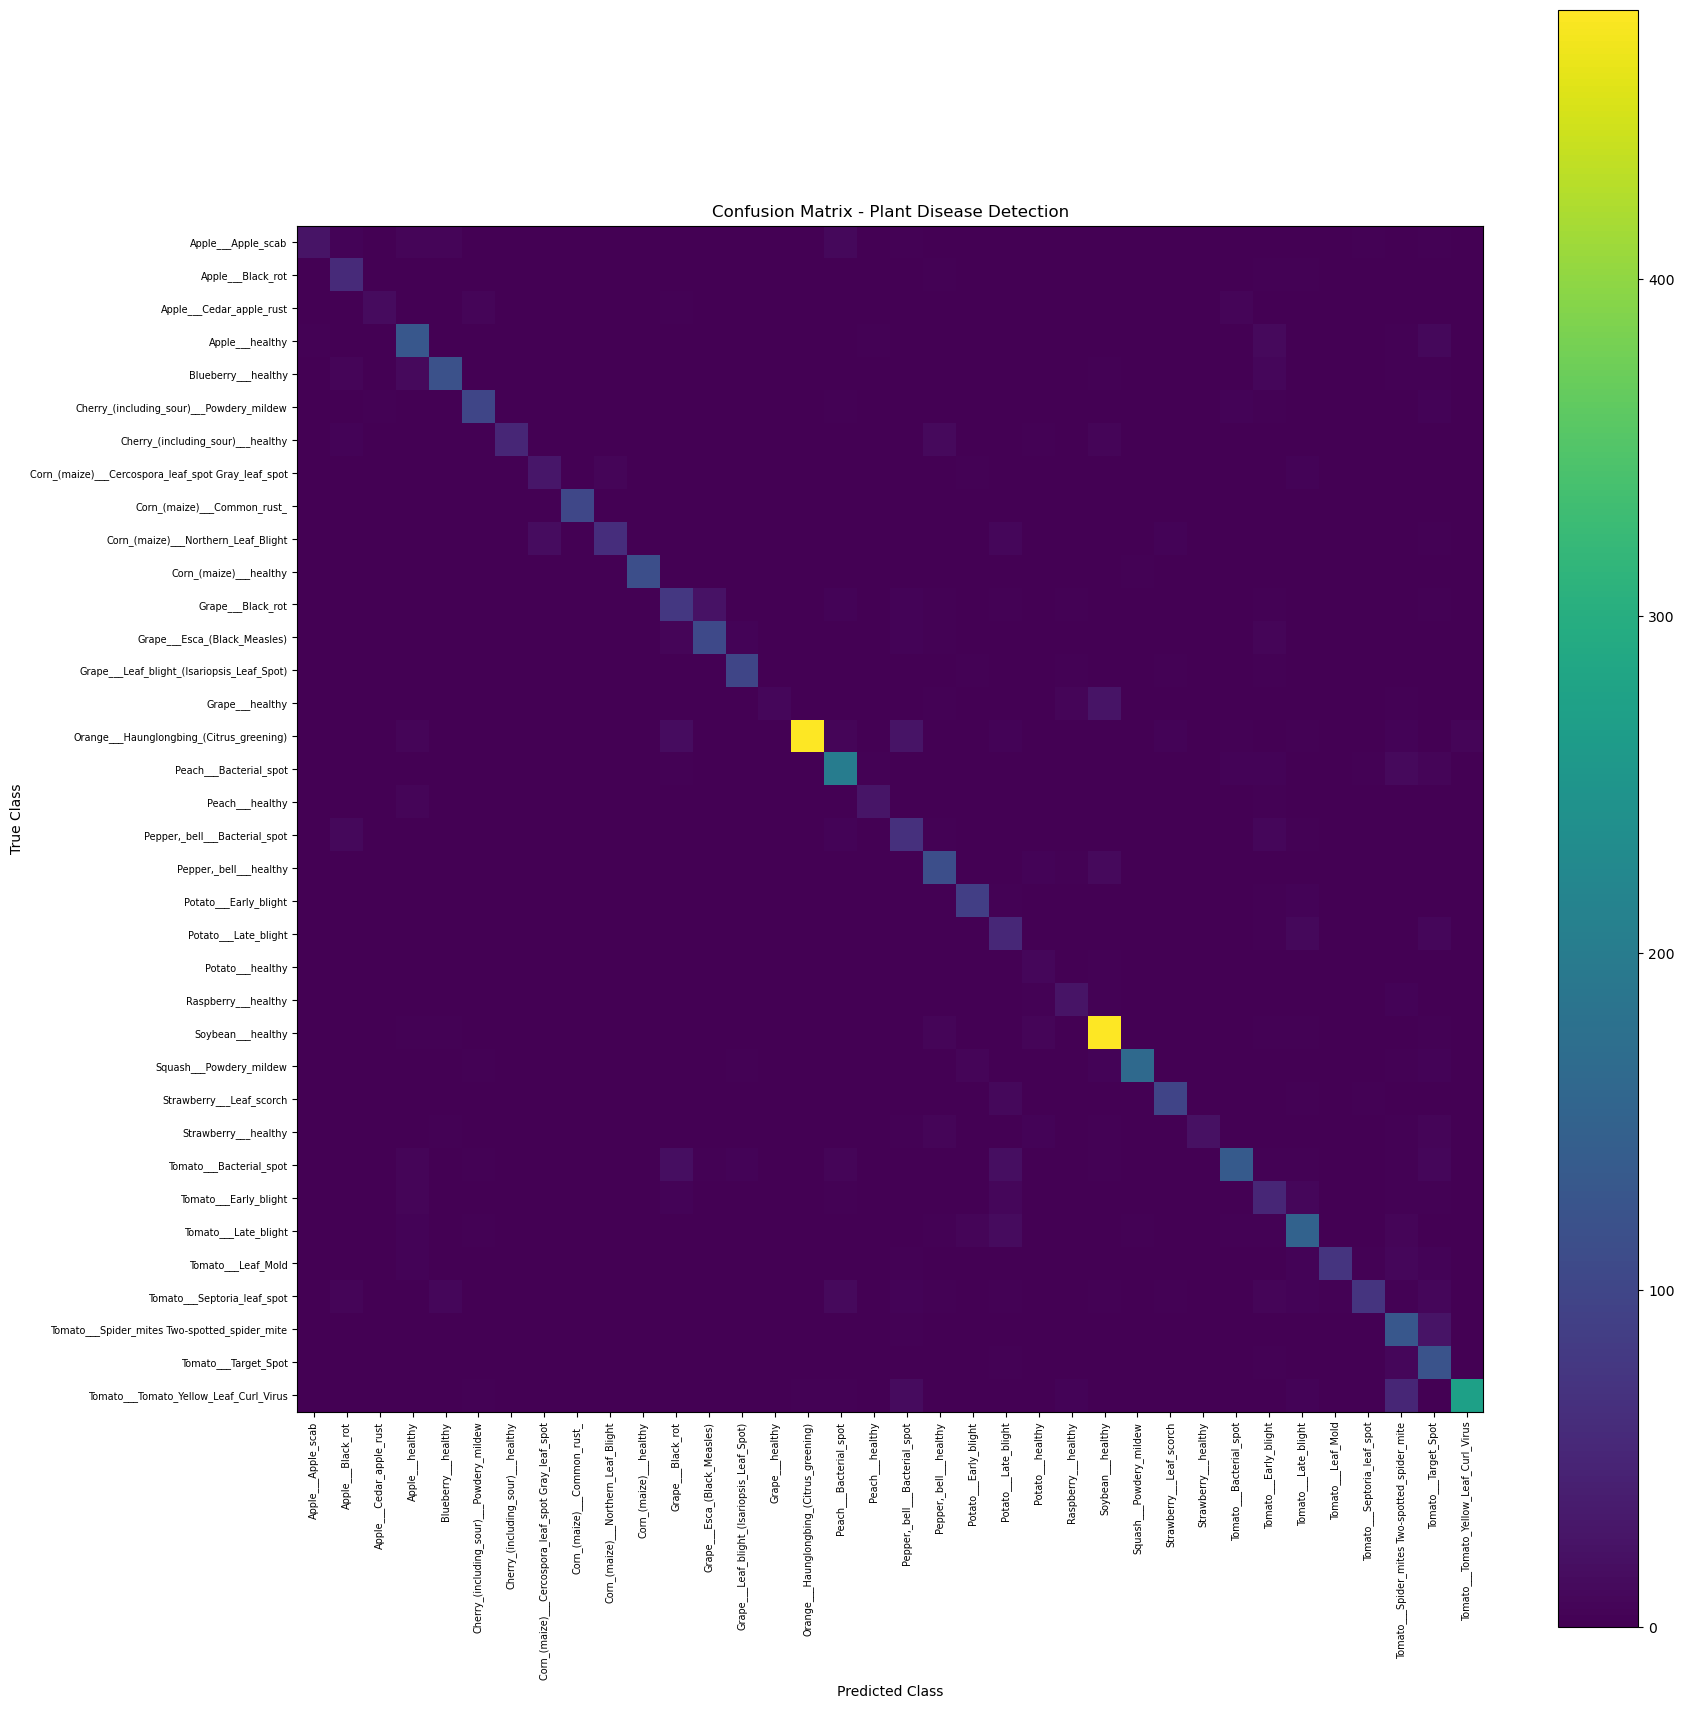

In [112]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true_final, y_pred_final)

plt.figure(figsize=(18, 18))
plt.imshow(cm)
plt.title("Confusion Matrix - Plant Disease Detection")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.colorbar()

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=90,
    fontsize=7
)

plt.yticks(
    np.arange(len(class_names)),
    class_names,
    fontsize=7
)

plt.tight_layout()
plt.show()

In [113]:
def predict_plant_disease(image_path):

    img = Image.open(image_path).convert("RGB")
    img = img.resize((256, 256))

    img_array = np.array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Use FINAL trained model
    predictions = final_model.predict(img_array, verbose=0)[0]

    predicted_index = np.argmax(predictions)
    predicted_class = class_names[predicted_index]

    confidence = predictions[predicted_index] * 100

    # Get disease information
    info = disease_info[predicted_class]

    plant, disease = predicted_class.split("___")

    return {
        "plant": plant.replace("_", " "),
        "disease": disease.replace("_", " "),
        "confidence": round(float(confidence), 2),
        "symptoms": info["symptoms"],
        "prevention": info["prevention"],
        "management": info["management"]
    }

In [114]:
result = predict_plant_disease(image_path)

print("Plant:", result["plant"])
print("Disease:", result["disease"])
print("Confidence:", result["confidence"], "%")

print("\nSymptoms:")
for x in result["symptoms"]:
    print("-", x)

print("\nPrevention:")
for x in result["prevention"]:
    print("-", x)

print("\nManagement:")
for x in result["management"]:
    print("-", x)

Plant: Tomato
Disease: Late blight
Confidence: 96.3 %

Symptoms:
- Small water-soaked areas rapidly enlarge into brown or purple-brown blotches
- White-gray fungal growth may appear under humid conditions
- Leaves can die rapidly
- Fruit may develop firm brown lesions

Prevention:
- Use healthy disease-free transplants
- Remove volunteer tomato and potato plants
- Avoid overhead irrigation where possible
- Maintain good air circulation

Management:
- Remove infected plant material promptly
- Monitor frequently during cool and humid weather
- Destroy infected crop debris after harvest
- Use locally recommended fungicide programs when necessary


In [115]:
import os
import random

test_classes = [
    "Apple___Apple_scab",
    "Corn_(maize)___Common_rust_",
    "Grape___Black_rot",
    "Potato___Late_blight",
    "Tomato___Late_blight"
]

print("Testing multiple plant classes...\n")

for true_class in test_classes:

    class_folder = os.path.join(dataset_path, true_class)

    images = [
        f for f in os.listdir(class_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    image_file = random.choice(images)
    image_path_test = os.path.join(class_folder, image_file)

    result = predict_plant_disease(image_path_test)

    print("Actual :", true_class)
    print("Predicted:", result["plant"], "-", result["disease"])
    print("Confidence:", result["confidence"], "%")
    print("-" * 60)

Testing multiple plant classes...

Actual : Apple___Apple_scab
Predicted: Apple - healthy
Confidence: 84.8 %
------------------------------------------------------------
Actual : Corn_(maize)___Common_rust_
Predicted: Corn (maize) - Common rust 
Confidence: 100.0 %
------------------------------------------------------------
Actual : Grape___Black_rot
Predicted: Tomato - Spider mites Two-spotted spider mite
Confidence: 79.29 %
------------------------------------------------------------
Actual : Potato___Late_blight
Predicted: Potato - Late blight
Confidence: 95.34 %
------------------------------------------------------------
Actual : Tomato___Late_blight
Predicted: Tomato - Late blight
Confidence: 86.67 %
------------------------------------------------------------
